# **Tutorial 08 - Numerical Integration and ODE Parameter Estimation**: Supplementary Interactive Material

-------------------------------------------------------------------------

In Tutorial 07, we fitted a model by evaluating an explicit formula at each trial
parameter. What changes when our model is a differential equation, and we have
to compute its solution before we can compare it with data?

Run the cells in order. Each fitting example has an **Observations** slider,
initially set to **500**, with a range of **10–1000**. Release the slider to
generate the observations and repeat the fit. As we vary the amount of data,
we will ask which features of the trajectory help us determine each parameter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
import ipywidgets as widgets
from IPython.display import HTML, display

## 1. Review: solving an initial value problem

A differential equation tells us how a quantity changes, rather than giving
its value directly. For an initial value problem,

$$y'(t)=f(t,y(t)),\qquad y(t_0)=y_0,$$

we know where the trajectory begins and can evaluate its slope there. How can
we use that information to approximate the trajectory at later times?

Integrating the differential equation over one time interval gives

$$y(t_{n+1})=y(t_n)+\int_{t_n}^{t_{n+1}} f(t,y(t))\,dt.$$

**Forward Euler** approximates the slope throughout the interval by its
value at the beginning. With step size $h=t_{n+1}-t_n$, this gives

$$y_{n+1}=y_n+h f(t_n,y_n).$$

Geometrically, we follow the tangent line for a short distance, compute a new
slope, and repeat. A smaller step gives the slope less time to change before
we evaluate it again. For a smooth solution and a sufficiently small step,
Euler's global error over a fixed interval is $O(h)$: halving the step size
should roughly halve the error.

### Example 01: logistic growth

Consider a population that initially grows rapidly but has limited resources:

$$y'=r y\left(1-\frac{y}{K}\right),\qquad y(0)=y_0.$$

The parameter $r$ is the growth rate and $K$ is the carrying capacity. When
$y$ is small compared with $K$, the factor $1-y/K$ is close to one and growth
is approximately exponential. As the population approaches $K$, that factor
approaches zero and growth slows.

We use $r=1$, $K=3$, and $y_0=0.2$. This example also has an exact solution,

$$y(t)=\frac{K}{1+(K/y_0-1)e^{-rt}},$$

so we can measure the numerical error directly. The code below compares Euler
steps of $0.5$ and $0.05$ against this reference over the same time interval.

**Before running the cell: where along the trajectory would you expect the
straight-line approximation to be least accurate?**

h=0.5: maximum error = 0.2571
h=0.05: maximum error = 0.0261


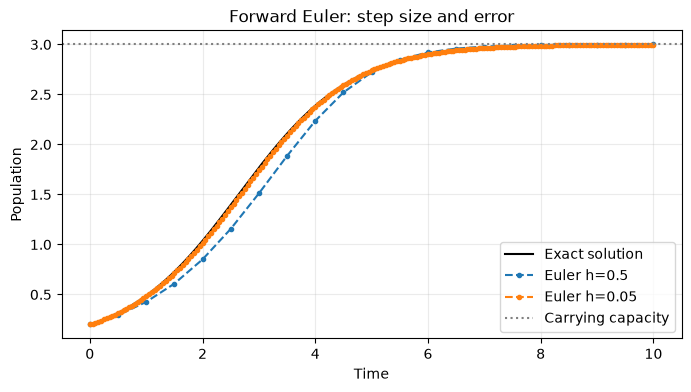

In [2]:
def logistic_rhs(t, y, r=1.0, K=3.0):
    return r * y * (1 - y / K)

def logistic_exact(t, r=1.0, K=3.0, y0=0.2):
    return K / (1 + (K / y0 - 1) * np.exp(-r * np.asarray(t)))

def euler(f, t0, T, y0, h):
    # Choose equal steps no larger than h and land exactly at T.
    if h <= 0 or T <= t0:
        raise ValueError("Require h > 0 and T > t0")
    times = np.linspace(t0, T, int(np.ceil((T - t0) / h)) + 1)
    values = np.empty(len(times))
    values[0] = y0
    for i, step in enumerate(np.diff(times)):
        values[i + 1] = values[i] + step * f(times[i], values[i])
    return times, values

fine_time = np.linspace(0, 10, 400)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fine_time, logistic_exact(fine_time), 'k-', label='Exact solution')
for h in (0.5, 0.05):
    times, values = euler(logistic_rhs, 0, 10, 0.2, h)
    ax.plot(times, values, '.--', label=f'Euler h={h}')
    print(f'h={h}: maximum error = {np.max(np.abs(values - logistic_exact(times))):.4f}')
ax.axhline(3, color='gray', linestyle=':', label='Carrying capacity')
ax.set(xlabel='Time', ylabel='Population', title='Forward Euler: step size and error')
ax.legend(); ax.grid(alpha=0.25)
plt.show()

### Improving the slope estimate: midpoint Runge–Kutta


We can also improve how we use each step. Euler uses only the slope at the
beginning, even though the trajectory may bend appreciably before the end.
What if we first estimate a point halfway through the interval and evaluate
the slope there?

This gives the **midpoint Runge–Kutta method (RK2)**:

$$\begin{aligned}
k_1&=f(t_n,y_n),\\
k_2&=f\!\left(t_n+\frac h2,\;y_n+\frac h2 k_1\right),\\
y_{n+1}&=y_n+h k_2.
\end{aligned}$$

The first slope $k_1$ predicts the midpoint; the second slope $k_2$ advances
the solution over the full step. We now evaluate the right-hand side twice
per step, but the global error for smooth problems is $O(h^2)$. In the regime
where this estimate applies, halving $h$ reduces the error by roughly four.

### Example 02: a damped pendulum

Logistic growth approaches a steady value. An oscillating system gives us
another way to see integration error: a numerical method can change the
amplitude or timing of successive swings.

For a pendulum, write the second-order equation as a system for the angle
$\theta$ and angular velocity $\omega$:

$$\begin{aligned}
\dot\theta&=\omega,\\
\dot\omega&=-\frac gL\sin\theta-\gamma\omega.
\end{aligned}$$

Gravity pulls the pendulum toward its lowest position, while the damping
term opposes its motion. Here $L=1$ m, $g=9.81$ m/s $^2$, and
$\gamma=0.15$ s $^{-1}$. We release it from $\theta(0)=\pi/3$ with zero
angular velocity. Because damping removes energy, the physical oscillations
should gradually decrease in amplitude.

The animation applies Euler and RK2 to the same initial state, both with
$h=0.08$ s.


In [3]:
# Pendulum parameters
L = 1.0      # length (m)
g = 9.81     # gravity (m/s^2)
damping = 0.15
theta0 = np.pi/3   # initial angle (rad)
omega0 = 0.0       # initial angular velocity (rad/s)

# ODE system for pendulum
def pendulum_ode(state, t):
    theta, omega = state
    theta_dot = omega
    omega_dot = -(g/L)*np.sin(theta) - damping*omega
    return np.array([theta_dot, omega_dot])

# Integrators
def euler_step(f, state, t, dt):
    return state + dt * f(state, t)

def rk2_step(f, state, t, dt):
    k1 = f(state, t)
    k2 = f(state + 0.5*dt*k1, t + 0.5*dt)
    return state + dt * k2

# Time discretization
dt = 0.08
t_max = 10.0
t = np.arange(0, t_max, dt)
n_steps = len(t)

# Arrays for storing solutions
theta_euler = np.zeros(n_steps)
theta_rk2   = np.zeros(n_steps)

# Initial states
state_euler = np.array([theta0, omega0])
state_rk2   = np.array([theta0, omega0])
theta_euler[0], _ = state_euler
theta_rk2[0], _   = state_rk2

# Integrate
for i in range(1, n_steps):
    state_euler = euler_step(pendulum_ode, state_euler, t[i-1], dt)
    state_rk2   = rk2_step(pendulum_ode, state_rk2, t[i-1], dt)
    theta_euler[i] = state_euler[0]
    theta_rk2[i]   = state_rk2[0]

# Animation 2: Angle vs Time
fig2, ax2 = plt.subplots(figsize=(12, 6))

euler_angle_line, = ax2.plot([], [], 'r-', linewidth=2, label='Euler')
rk2_angle_line,   = ax2.plot([], [], 'b--', linewidth=2, label='RK2')
point_euler,      = ax2.plot([], [], 'ro', markersize=8)
point_rk2,        = ax2.plot([], [], 'bo', markersize=8)

ax2.set_xlim(0, t_max)
ax2.set_ylim(-2*theta0, 2*theta0)
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Angle θ (rad)")
ax2.set_title("Angle vs Time Animation: Euler vs RK2")
ax2.grid(True, alpha=0.3)
ax2.legend()

def update_sinusoid(frame):
    euler_angle_line.set_data(t[:frame], theta_euler[:frame])
    rk2_angle_line.set_data(t[:frame], theta_rk2[:frame])
    if frame > 0:
        point_euler.set_data([t[frame-1]], [theta_euler[frame-1]])
        point_rk2.set_data([t[frame-1]], [theta_rk2[frame-1]])
    return euler_angle_line, rk2_angle_line, point_euler, point_rk2

ani2 = FuncAnimation(fig2, update_sinusoid, frames=range(0, n_steps, 5),
                     interval=50, blit=True, repeat=True)

plt.close(fig2)  # prevent duplicate static plot

# Show in Jupyter
HTML(ani2.to_jshtml())



> **Explore:** Reduce `dt` from `0.08` to `0.04` and rerun the animation.
> How does the difference between the methods change? What additional work
> does each method perform when the time step is halved?

## 2. From forward simulation to parameter estimation

So far, the model parameters have been given to us. We supplied a growth rate
or damping coefficient and computed a trajectory. This is the **forward
problem**. Suppose instead that we measure a population or displacement at
several times. Can we infer the parameters that produced those measurements?

This is an **inverse problem**. Write the observations as

$$d_i=y(t_i;\mathbf p)+\epsilon_i,\qquad i=1,\ldots,N,$$

where $\mathbf p$ contains the unknown parameters and $\epsilon_i$ represents
measurement noise. In these examples, the initial state is known and the
noise is independent Gaussian noise with mean zero and a fixed standard
deviation. We estimate the parameters from the observations; the true
parameters are used to generate data and assess the result.

### Compare a trial trajectory with the observations

Recall the residuals from Tutorial 07: prediction minus observation. Here a
residual depends on the solution of an ODE,

$$r_i(\mathbf p)=y(t_i;\mathbf p)-d_i.$$

We choose parameters that minimize the **mean squared residual**,

$$\min_{\mathbf p} L(\mathbf p),\qquad
L(\mathbf p)=\frac1N\sum_{i=1}^N r_i(\mathbf p)^2.$$

For any fixed dataset, dividing the sum by $N$ does not change its minimizer.
It does keep the scale of the loss and its gradient comparable when we change
the number of observations. Otherwise, adding observations would also change
the scale of our gradient-descent updates.

The fitting loop now contains an integration loop: each trial parameter vector
requires solving the ODE, evaluating the solution at the observation times,
and forming the residuals. This makes an objective evaluation more expensive
than evaluating the explicit formula in Tutorial 07.

### Observation times and integration steps

We use `solve_ivp` for the forward solves. It adjusts its internal time steps
to meet accuracy tolerances and returns predictions at the requested times
through `t_eval`. The tolerances here make numerical error small compared
with the observation noise.

The observation slider changes how many measurements we collect over the same
time window. It does not prescribe the solver's internal step size. These are
two different questions: how accurately do we compute a trajectory, and how
much data do we have to estimate its parameters?

The helpers below handle the forward solve and slider display. We hold the
noise level and random seed fixed for reproducibility. Different sample counts
use different evenly spaced time grids, so their datasets are separate
experiments rather than nested subsets of a single dataset.

In [4]:
def simulate(rhs, parameters, times, initial_state):
    sol = solve_ivp(rhs, (0.0, float(times[-1])), initial_state,
                    args=tuple(parameters), t_eval=times, rtol=1e-8, atol=1e-10)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.y[0]

def observation_slider(callback):
    slider = widgets.IntSlider(value=500, min=10, max=1000, step=10,
                               description='Observations', continuous_update=False,
                               style={'description_width': 'initial'})
    output = widgets.interactive_output(callback, {'n_observations': slider})
    display(widgets.VBox([slider, output]))
    return slider, output

### Example 03: estimating logistic growth parameters

Return to the logistic population, now treating $r$ and $K$ as unknown. We keep
the initial population $y_0=0.2$ known and observe the population over
$0\leq t\leq10$, adding Gaussian noise with standard deviation $0.08$.

The shape of the trajectory suggests how the parameters might be recovered.
The growth rate affects how quickly the population rises, while the carrying
capacity sets its eventual plateau. 

We start the fit at $(r,K)=(0.6,2.0)$ and use `least_squares`, a solver designed
to work with a vector of residuals.  We restrict
$0.05\leq r\leq3$ and $0.3\leq K\leq8$ 

The plot compares the observations, true trajectory, and fitted trajectory.

**Move the slider from 500 observations to 10. Does the fitted curve still
capture both the initial growth and the plateau? How much do the estimated
parameters change?**

In [ ]:
def fit_logistic(n_observations=500):
    times = np.linspace(0, 10, n_observations)
    true_parameters = np.array([1.0, 3.0])
    observed = simulate(logistic_rhs, true_parameters, times, [0.2])
    observed += np.random.default_rng(21).normal(0, 0.5, n_observations)

    def residual(parameters):
        return simulate(logistic_rhs, parameters, times, [0.2]) - observed

    fit = least_squares(residual, [0.6, 2.0], bounds=([0.05, 0.3], [3.0, 8.0]))
    if not fit.success:
        raise RuntimeError(fit.message)
    dense = np.linspace(0, 10, 400)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(times, observed, s=12, alpha=0.35, label=f'{n_observations} observations')
    ax.plot(dense, logistic_exact(dense), 'k-', label='True model')
    ax.plot(dense, simulate(logistic_rhs, fit.x, dense, [0.2]), 'r--', label='Fitted model')
    ax.set(xlabel='Time', ylabel='Population', title='Estimating logistic growth parameters')
    ax.legend(); ax.grid(alpha=0.25)
    plt.show()
    print(f'True: r=1.0000, K=3.0000 | Fit: r={fit.x[0]:.4f}, K={fit.x[1]:.4f}')
    print(f'Absolute parameter errors: {np.abs(fit.x - true_parameters)}')
    print(f'Mean squared residual: {np.mean(fit.fun**2):.5f}')
    return fit

logistic_controls = observation_slider(fit_logistic)

## 3. Fitting a damped oscillator
 We now consider a
system whose observations contain both oscillation and decay. A damped spring
obeys

$$x''+2\zeta\omega x'+\omega^2x=0,$$

where $x$ is displacement, $\zeta$ is the damping ratio, and $\omega$ is the
natural angular frequency. In this section $\omega$ is a model parameter;
in the pendulum example it denoted the time-dependent angular velocity.

To integrate this equation, introduce velocity $v=x'$:

$$\begin{aligned}
x'&=v,\\
v'&=-2\zeta\omega v-\omega^2x.
\end{aligned}$$

We release the system from $x(0)=1$ with $v(0)=0$. The synthetic observations
use $\zeta=0.2$, $\omega=2$, and displacement noise with standard deviation
$0.5$. These parameters give an underdamped motion: the displacement
oscillates while its envelope decreases.

The spacing between peaks carries information about frequency, while their
decay carries information about damping.

### Revisit gradient descent

Can we recover both parameters with the gradient-descent idea from Tutorial 07?
For $\mathbf p=(\zeta,\omega)^\top$, the basic update is

$$\mathbf p_{k+1}=\mathbf p_k-\alpha_k\nabla L(\mathbf p_k).$$

Here we do not have an explicit formula for the model derivatives, instead, we perturb each parameter, solve the ODE again,
and approximate the derivative by a **central finite difference**:

$$\frac{\partial L}{\partial p_j}(\mathbf p)
\approx\frac{L(\mathbf p+\delta\mathbf e_j)-L(\mathbf p-\delta\mathbf e_j)}{2\delta},
\qquad\delta=10^{-4}.$$

The vector $\mathbf e_j$ changes only parameter $j$. With two parameters,
one gradient estimate needs four objective evaluations, each with its own
ODE solve. Making $\delta$ too small can amplify numerical error in these
differences.

### Choose a step and compare the methods

A full gradient step can be too large. The implementation begins with step size
$\alpha_k=1$ and repeatedly halves it until a sufficient-decrease condition
is met. This is **backtracking**. We also project each proposed point onto
the bounds $0.01\leq\zeta\leq2$ and $0.2\leq\omega\leq5$ by clipping its
coordinates. The candidate update is therefore

$$\mathbf p_{\mathrm{trial}}=
\operatorname{clip}_{[\mathbf l,\mathbf u]}
\left(\mathbf p_k-\alpha_k\nabla L(\mathbf p_k)\right).$$

The run stops after at most 100 accepted updates, when an update has norm
below $10^{-7}$, or when backtracking cannot find an acceptable step. A small
update alone does not establish that we have found a global minimum.

For comparison, we also fit with the bounded `least_squares` solver. Both
methods receive the same observations, bounds, and starting guess
$(\zeta,\omega)=(0.5,1.0)$. Their stopping rules differ, so this comparison
shows the resulting fits and gradient-descent progress, rather than measuring
which implementation is faster. Both methods solve the same fitting problem
and both can depend on the starting point.

**Compare the fitted curves and the loss plot. If the curves overlap, do the
printed parameters also agree? What changes when only 10 observations are
available to describe the oscillations?**

In [ ]:
def damped_oscillator(t, state, zeta, omega):
    x, v = state
    return [v, -2 * zeta * omega * v - omega**2 * x]

def gradient_descent(loss, initial, lower, upper, max_iterations=100):
    parameters = np.array(initial, dtype=float)
    history = [loss(parameters)]
    for _ in range(max_iterations):
        h = 1e-4
        gradient = np.array([
            (loss(parameters + h * direction) - loss(parameters - h * direction)) / (2 * h)
            for direction in np.eye(len(parameters))
        ])
        step = 1.0
        for _ in range(25):
            candidate = np.clip(parameters - step * gradient, lower, upper)
            value = loss(candidate)
            if value <= history[-1] + 1e-4 * np.dot(gradient, candidate - parameters):
                break
            step *= 0.5
        else:
            break
        change = np.linalg.norm(candidate - parameters)
        parameters = candidate
        history.append(value)
        if change < 1e-7:
            break
    return parameters, np.array(history)

def fit_oscillator(n_observations=500):
    times = np.linspace(0, 10, n_observations)
    true_parameters = np.array([0.2, 2.0])
    initial_state = [1.0, 0.0]
    observed = simulate(damped_oscillator, true_parameters, times, initial_state)
    observed += np.random.default_rng(0).normal(0, 0.5, n_observations)

    def residual(parameters):
        return simulate(damped_oscillator, parameters, times, initial_state) - observed

    def loss(parameters):
        return np.mean(residual(parameters)**2)

    lower, upper = np.array([0.01, 0.2]), np.array([2.0, 5.0])
    initial = [0.5, 1.0]
    gd_parameters, history = gradient_descent(loss, initial, lower, upper)
    fit = least_squares(residual, initial, bounds=(lower, upper))
    if not fit.success:
        raise RuntimeError(fit.message)

    dense = np.linspace(0, 10, 500)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(times, observed, s=10, alpha=0.35, label=f'{n_observations} observations')
    for parameters, style, label in [(true_parameters, 'k-', 'True model'),
                                     (gd_parameters, 'r--', 'Gradient descent'),
                                     (fit.x, 'b:', 'Least squares')]:
        axes[0].plot(dense, simulate(damped_oscillator, parameters, dense, initial_state),
                     style, label=label)
    axes[0].set(xlabel='Time', ylabel='Displacement', title='Damped oscillator fit')
    axes[0].legend()
    axes[1].semilogy(history, label='Gradient descent')
    axes[1].axhline(loss(fit.x), color='blue', linestyle=':', label='Least squares')
    axes[1].set(xlabel='Iteration', ylabel='Mean squared residual', title='Optimization progress')
    axes[1].legend()
    for ax in axes:
        ax.grid(alpha=0.25)
    fig.tight_layout(); plt.show()
    print('True: zeta=0.2000, omega=2.0000')
    for label, parameters in [('Gradient descent', gd_parameters), ('Least squares', fit.x)]:
        print(f'{label}: zeta={parameters[0]:.4f}, omega={parameters[1]:.4f}, MSE={loss(parameters):.5f}')
    return gd_parameters, history, fit

oscillator_controls = observation_slider(fit_oscillator)

### What does the convergence plot tell us?

The right panel records the mean squared residual after each accepted
gradient-descent update, including the initial guess. The horizontal line
shows the loss reached by `least_squares`. When gradient descent reaches
that line, the two methods have found fits with similar residual error.
They can still require very different amounts of work to get there.

The loss need not approach zero: we added noise, so the true trajectory does
not pass through every observation. With many observations and a good fit,
the mean squared residual should be on the scale of the noise variance,
$0.5^2$. Driving the training residual lower does not by itself establish
that the parameters are closer to their true values.

> **Explore:** Compare 10, 100, 500, and 1000 observations in both fitting
> examples. Do the parameter estimates improve monotonically as observations
> are added? Why might the noise in a particular dataset interrupt that trend?
>
> In the logistic example, change the observation window to end at $t=2$
> instead of $t=10$ and rerun the cell. Does increasing the observation count
> compensate for never seeing the plateau?
>
> Change the oscillator's initial parameter guess and rerun its cell. Do both
> methods reach the same fit? Inspect the loss and parameter values as well
> as the curves.

The observation experiments return us to the distinction between forward and
inverse problems. Smaller integration steps or tighter tolerances help us
compute a trajectory accurately. More informative measurements help us infer
which trajectory generated the data. A successful fit needs both an adequate
forward solve and observations that constrain the parameters we seek.